In [ ]:
import pandas as pd


In [ ]:
df=pd.read_csv('/content/FMCG_2022_2024.csv')

In [ ]:
print("Initial Shape:", df.shape)


In [ ]:
print (df)

In [ ]:
df['date']=pd.to_datetime(df['date'],errors='coerce')

In [ ]:
df_clean=df[(df['units_sold']>0) & (df['price_unit']>0) & (df['date'].notna())].copy()

In [ ]:
print("Shape after removing invalid price/quantity/date:", df_clean.shape)


In [ ]:
before_dup=df_clean.shape[0]
df_clean=df_clean.drop_duplicates()
after_dup=df_clean.shape[0]

In [ ]:
print("Removed duplicates:", before_dup - after_dup)

In [ ]:
print("Final Clean Shape:", df_clean.shape)


In [ ]:
df_clean['year'] = df_clean['date'].dt.year
df_clean['month'] = df_clean['date'].dt.month
df_clean['quarter'] = df_clean['date'].dt.quarter

In [ ]:
df_clean.tail()

In [ ]:
df_clean['category'].value_counts()

In [ ]:
df_yogurt=df_clean[df_clean['category']=='Yogurt'].copy()
print(df_yogurt.shape)
df_yogurt.head()

In [ ]:
df_yogurt['price_unit'].describe()

In [ ]:
df_yogurt['units_sold'].describe()

In [ ]:
df_yogurt.groupby('promotion_flag')['units_sold'].mean()

In [ ]:
df_yogurt['date'].min(), df_yogurt['date'].max()

In [ ]:
df_yogurt[['price_unit', 'units_sold']].corr()

In [ ]:
df_yogurt_no_promo = df_yogurt[df_yogurt['promotion_flag'] == 0]
df_yogurt_no_promo[['price_unit', 'units_sold']].corr()

In [ ]:
df_yogurt['sku'].value_counts().head(5)

In [ ]:
df_sku = df_yogurt[df_yogurt['sku'] == 'YO-029'].copy()

print(df_sku.shape)


In [ ]:
df_sku[['price_unit','units_sold']].describe()

In [ ]:
df_sku[['price_unit','units_sold']].corr()

In [ ]:
df_sku['price_unit'].value_counts().sort_index()

In [ ]:
import numpy as np

df_sku['log_price'] = np.log(df_sku['price_unit'])
df_sku['log_units'] = np.log(df_sku['units_sold'])

In [ ]:
df_sku[['log_price','log_units']].corr()

In [ ]:
df_sku=df_sku.sort_values('date')
df_sku['time_index']=range(len(df_sku))

In [ ]:
import statsmodels.api as sm

In [ ]:
X = df_sku[['log_price','promotion_flag','time_index']]

X = sm.add_constant(X)

y = df_sku['log_units']

model = sm.OLS(y, X).fit()

In [ ]:
print(model.summary())

In [ ]:
df_nonpromo = df_sku[df_sku['promotion_flag']==0]


In [ ]:
import statsmodels.api as sm
import numpy as np
import pandas as pd

df_nonpromo = df_nonpromo.copy()
df_nonpromo = df_nonpromo.sort_values('date')
df_nonpromo['time_index'] = range(len(df_nonpromo))

df_nonpromo['log_price'] = np.log(df_nonpromo['price_unit'])
df_nonpromo['log_units'] = np.log(df_nonpromo['units_sold'])

X_np = df_nonpromo[['log_price','time_index']]
X_np = sm.add_constant(X_np)

y_np = df_nonpromo['log_units']

model_np = sm.OLS(y_np, X_np).fit()
__builtins__.print(model_np.summary())

In [ ]:
df_promo = df_sku[df_sku['promotion_flag']==1]

In [ ]:
df_promo = df_promo.copy()
df_promo = df_promo.sort_values('date')
df_promo['time_index'] = range(len(df_promo))

df_promo['log_price'] = np.log(df_promo['price_unit'])
df_promo['log_units'] = np.log(df_promo['units_sold'])

X_p = df_promo[['log_price','time_index']]
X_p = sm.add_constant(X_p)

y_p = df_promo['log_units']

model_p = sm.OLS(y_p, X_p).fit()


In [ ]:
__builtins__.print(model_p.summary())

In [ ]:
df_sku02 = df_yogurt[df_yogurt['sku'] == 'YO-005'].copy()

__builtins__.print(df_sku02.shape)

In [ ]:
df_sku02[['price_unit','units_sold']].describe()

In [ ]:
df_sku02[['price_unit','units_sold']].corr()

In [ ]:
df_sku02['price_unit'].value_counts().sort_index()

In [ ]:
import numpy as np

df_sku02['log_price'] = np.log(df_sku02['price_unit'])
df_sku02['log_units'] = np.log(df_sku02['units_sold'])

In [ ]:
df_sku02[['log_price','log_units']].corr()

In [ ]:
# Step 1: Filter SKU
df_sku02 = df_yogurt[df_yogurt['sku'] == 'YO-005'].copy()

# Step 2: Sort and create time index
df_sku02 = df_sku02.sort_values('date')
df_sku02['time_index'] = range(len(df_sku02))

# Step 3: Create log variables
import numpy as np

df_sku02['log_price'] = np.log(df_sku02['price_unit'])
df_sku02['log_units'] = np.log(df_sku02['units_sold'])

# Step 4: Run regression
import statsmodels.api as sm

X = df_sku02[['log_price','promotion_flag','time_index']]
X = sm.add_constant(X)

y = df_sku02['log_units']

model = sm.OLS(y, X).fit()
__builtins__.print(model.summary())

In [ ]:
df_snack = df[df['category'] == 'SnackBar']
df_snack['sku'].value_counts().head(5)

In [ ]:
df_sku_snack = df_snack[df_snack['sku'] == 'SN-027'].copy()

# Remove zero sales
df_sku_snack = df_sku_snack[df_sku_snack['units_sold'] > 0].copy()

# Sort by date
df_sku_snack = df_sku_snack.sort_values('date')

# Time index
df_sku_snack['time_index'] = range(len(df_sku_snack))

# Recreate logs
df_sku_snack['log_price'] = np.log(df_sku_snack['price_unit'])
df_sku_snack['log_units'] = np.log(df_sku_snack['units_sold'])

# Regression
X = df_sku_snack[['log_price','promotion_flag','time_index']]
X = sm.add_constant(X)
y = df_sku_snack['log_units']

model = sm.OLS(y, X).fit()
__builtins__.print(model.summary())

In [ ]:
df_sku_snack.groupby('promotion_flag')['price_unit'].describe()

In [ ]:
df_sku_snack[df_sku_snack['promotion_flag']==0]['price_unit'].nunique()

Now lets check seasonality after doing 3 sku analysis

In [ ]:
df_juice = df[df['category'] == 'Juice']
df_juice['sku'].value_counts().head(5)

In [ ]:
# Filter SKU
df_juice_sku = df[(df['category'] == 'Juice') & (df['sku'] == 'JU-021')].copy()

# Remove zero sales (important for log)
df_juice_sku = df_juice_sku[df_juice_sku['units_sold'] > 0]

# Sort by date
df_juice_sku = df_juice_sku.sort_values('date')

# Time index
df_juice_sku['time_index'] = range(len(df_juice_sku))

# Log variables
import numpy as np
df_juice_sku['log_price'] = np.log(df_juice_sku['price_unit'])
df_juice_sku['log_units'] = np.log(df_juice_sku['units_sold'])

In [ ]:
# Extract month
df_juice_sku['month'] = df_juice_sku['date'].dt.month

# Create month dummies
month_dummies = pd.get_dummies(df_juice_sku['month'], prefix='month', drop_first=True)

# Combine
df_model = pd.concat([df_juice_sku, month_dummies], axis=1)

In [ ]:
import statsmodels.api as sm

X_vars = ['log_price', 'promotion_flag', 'time_index'] + list(month_dummies.columns)
X = df_model[X_vars].astype(float)
X = sm.add_constant(X)

y = df_model['log_units']

model = sm.OLS(y, X).fit()
__builtins__.print(model.summary())

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

def analyze_sku(df, sku_id):

    # Filter SKU
    sku_df = df[df['sku'] == sku_id].copy()

    # Remove zero sales (important for log)
    sku_df = sku_df[sku_df['units_sold'] > 0]

    # Sort time
    sku_df = sku_df.sort_values('date')

    # Create time index
    sku_df['time_index'] = np.arange(len(sku_df))

    # Log transform
    sku_df['log_units'] = np.log(sku_df['units_sold'])
    sku_df['log_price'] = np.log(sku_df['price_unit'])

    # Month dummies
    sku_df['month'] = sku_df['date'].dt.month
    month_dummies = pd.get_dummies(
        sku_df['month'],
        prefix='month',
        drop_first=True
    )

    sku_df = pd.concat([sku_df, month_dummies], axis=1)

    # X variables
    X_cols = ['log_price', 'promotion_flag', 'time_index'] \
             + list(month_dummies.columns)

    X = sku_df[X_cols].astype(float) # Explicitly cast to float
    X = sm.add_constant(X)

    y = sku_df['log_units']

    # Run regression
    model = sm.OLS(y, X).fit()

    return model

In [ ]:
def extract_metrics(model):

    elasticity = model.params['log_price']
    promo_effect = model.params['promotion_flag']
    trend = model.params['time_index']

    # Significant months
    month_effects = {
        k: v
        for k, v in model.params.items()
        if 'month_' in k
    }

    return {
        "elasticity": elasticity,
        "promo_effect": promo_effect,
        "trend": trend,
        "month_effects": month_effects
    }

In [ ]:
model = analyze_sku(df, "SN-027")

metrics = extract_metrics(model)

print(metrics)

In [ ]:
def classify_sku(metrics):

    elasticity = metrics['elasticity']
    promo = metrics['promo_effect']
    months = metrics['month_effects']

    significant_months = sum(
        abs(v) > 0.2
        for v in months.values()
    )

    if abs(elasticity) > 0.2:
        return "Price Sensitive"

    elif promo > 0.3:
        return "Promotion Driven"

    elif significant_months > 4:
        return "Seasonal SKU"

    else:
        return "Stable SKU"

In [ ]:
strategy = classify_sku(metrics)

print(strategy)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure df_juice_sku is defined for plotting
df_juice_sku = df[(df['category'] == 'Juice') & (df['sku'] == 'JU-021')].copy()
df_juice_sku = df_juice_sku[df_juice_sku['units_sold'] > 0]

plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df_juice_sku['price_unit'],
    y=df_juice_sku['units_sold'],
    alpha=0.3
)

plt.title("Price vs Demand (JU-021)")
plt.xlabel("Price")
plt.ylabel("Units Sold")

plt.show()

In [ ]:
plt.figure(figsize=(6,4))

sns.barplot(
    x='promotion_flag',
    y='units_sold',
    data=df_juice_sku
)

plt.title("Promotion Impact on Demand (JU-021)")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Average Units Sold")

plt.show()

In [ ]:
# Extract month
df_juice_sku['month'] = df_juice_sku['date'].dt.month

monthly_avg = df_juice_sku.groupby('month')['units_sold'].mean()

plt.figure(figsize=(8,5))

sns.lineplot(
    x=monthly_avg.index,
    y=monthly_avg.values,
    marker='o'
)

plt.title("Seasonality Pattern (JU-021)")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")

plt.show()

In [ ]:
def analyze_product(df, product_name):

    # Filter product category
    product_df = df[
        df['category'] == product_name
    ].copy()

    print(f"Analyzing Product: {product_name}")
    print("Number of Records:", len(product_df))

    return product_df

In [ ]:
milk_df = analyze_product(df, "Milk")

In [ ]:
def get_top_sku(product_df):

    top_sku = (
        product_df.groupby('sku')['units_sold']
        .sum()
        .sort_values(ascending=False)
        .index[0]
    )

    print("Top SKU:", top_sku)

    return top_sku

In [ ]:
def run_product_engine(df, product_name):

    # Step 1: Filter product
    product_df = df[df['category'] == product_name]

    # Step 2: Get top SKU
    top_sku = get_top_sku(product_df)

    # Step 3: Run model
    model = analyze_sku(product_df, top_sku)

    # Step 4: Extract metrics
    metrics = extract_metrics(model)

    # Step 5: Classify strategy
    strategy = classify_sku(metrics)

    print("\nStrategy:", strategy)

    return product_df, top_sku, metrics

In [ ]:
def visualize_product(product_df, top_sku):

    sku_df = product_df[
        product_df['sku'] == top_sku
    ].copy()

    # Month extraction
    sku_df['month'] = sku_df['date'].dt.month

    # --- Price vs Demand ---
    plt.figure(figsize=(8,5))

    sns.scatterplot(
        x=sku_df['price_unit'],
        y=sku_df['units_sold'],
        alpha=0.3
    )

    plt.title(f"Price vs Demand ({top_sku})")
    plt.show()

    # --- Promotion Impact ---
    plt.figure(figsize=(6,4))

    sns.barplot(
        x='promotion_flag',
        y='units_sold',
        data=sku_df
    )

    plt.title("Promotion Impact")
    plt.show()

    # --- Seasonality ---
    monthly_avg = (
        sku_df.groupby('month')['units_sold']
        .mean()
    )

    plt.figure(figsize=(8,5))

    sns.lineplot(
        x=monthly_avg.index,
        y=monthly_avg.values,
        marker='o'
    )

    plt.title("Seasonality Pattern")
    plt.show()

In [ ]:
def generate_insights(metrics, strategy):

    elasticity = metrics['elasticity']
    promo = metrics['promo_effect']

    print("\n📊 AI Insights:")

    # Price Insight
    if abs(elasticity) < 0.1:
        print("• Demand is not sensitive to price changes.")

    elif abs(elasticity) > 0.3:
        print("• Demand is highly price sensitive.")

    # Promotion Insight
    if promo > 0.3:
        print("• Promotions significantly boost demand.")

    # Strategy
    print(f"• Recommended Strategy: {strategy}")

In [ ]:
def product_ai(df, product_name):

    print("\n==========================")
    print(f"AI Analysis for: {product_name}")
    print("==========================")

    product_df, top_sku, metrics = run_product_engine(
        df,
        product_name
    )

    visualize_product(product_df, top_sku)

    strategy = classify_sku(metrics)

    generate_insights(metrics, strategy)

In [ ]:
product_ai(df, "Milk")

In [ ]:
product_ai(df, "Juice")


In [ ]:
product_ai(df, "ReadyMeal")


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

def build_sku_clusters(sku_metrics_df):

    features = [
        'elasticity',
        'promo_effect',
        'trend',
        'avg_price',
        'avg_units'
    ]

    X = sku_metrics_df[features]

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    kmeans = KMeans(
        n_clusters=4,
        random_state=42
    )

    sku_metrics_df['cluster'] = kmeans.fit_predict(X_scaled)

    return sku_metrics_df, kmeans

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

def train_classifier(data):

    X = data[[
        'elasticity',
        'promo_effect',
        'trend',
        'avg_price',
        'avg_units'
    ]]

    y = data['cluster']

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    model = RandomForestClassifier()

    model.fit(X_train, y_train)

    accuracy = model.score(X_test, y_test)

    print("Classifier Accuracy:", accuracy)

    return model

In [ ]:
from sklearn.ensemble import RandomForestRegressor

def train_demand_predictor(df):

    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day

    X = df[[
        'price_unit',
        'promotion_flag',
        'month',
        'day'
    ]]

    y = df['units_sold']

    model = RandomForestRegressor()

    model.fit(X, y)

    return model

In [ ]:
import pandas as pd
import numpy as np

all_sku_metrics = []

unique_skus = df_clean['sku'].unique()

for sku in unique_skus:
    try:
        # Filter for the current SKU
        current_sku_df = df_clean[df_clean['sku'] == sku].copy()

        # Ensure there's enough data for regression after filtering for positive units
        # OLS requires at least k+1 observations, where k is number of predictors (here 3 + 11 for months = 14) + 1 for const
        # So, minimum around 15-20 observations might be reasonable.
        # This is an approximation; the actual number depends on the number of month dummies that are actually created for a specific SKU
        # For now, a simpler check for sufficient data points > some threshold
        if len(current_sku_df[current_sku_df['units_sold'] > 0]) < 20: # Arbitrary threshold for meaningful regression
            continue

        # Calculate average price and units for clustering features
        avg_price = current_sku_df['price_unit'].mean()
        avg_units = current_sku_df['units_sold'].mean()

        # Run the regression model for the SKU
        model = analyze_sku(df_clean, sku)
        metrics = extract_metrics(model)

        all_sku_metrics.append({
            'sku': sku,
            'elasticity': metrics['elasticity'],
            'promo_effect': metrics['promo_effect'],
            'trend': metrics['trend'],
            'avg_price': avg_price,
            'avg_units': avg_units
        })

    except Exception as e:
        # print(f"Skipping SKU {sku} due to error: {e}") # Uncomment for debugging
        continue

sku_metrics_df = pd.DataFrame(all_sku_metrics)

# Only proceed with clustering if sku_metrics_df is not empty
if not sku_metrics_df.empty:
    sku_metrics_df, kmeans_model = build_sku_clusters(sku_metrics_df)
    print("SKU clusters built successfully.")

    import matplotlib.pyplot as plt
    import seaborn as sns

    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        x='elasticity',
        y='promo_effect',
        hue='cluster',
        data=sku_metrics_df,
        palette='viridis',
        s=100
    )
    plt.title("SKU Clustering Map: Elasticity vs. Promotion Effect")
    plt.xlabel("Price Elasticity")
    plt.ylabel("Promotion Effect")
    plt.grid(True)
    plt.show()
else:
    print("No sufficient SKU data to build clusters and plot.")

In [ ]:
sku_metrics_df

In [ ]:

categories = ["Juice", "SnackBar", "Milk"]

selected_df = df[
    df['category'].isin(categories)
]

sku_list = selected_df['sku'].unique()

sku_list = sku_list[:20]

print("Number of SKUs:", len(sku_list))
print(sku_list)

In [ ]:
sku_metrics_list = []

In [ ]:
for sku in sku_list:

    try:
        # Run regression
        model = analyze_sku(df, sku)

        # Extract metrics
        metrics = extract_metrics(model)

        # Get avg values
        sku_df = df[df['sku'] == sku]

        avg_price = sku_df['price_unit'].mean()
        avg_units = sku_df['units_sold'].mean()

        # Store results
        sku_metrics_list.append({
            "sku": sku,
            "elasticity": metrics['elasticity'],
            "promo_effect": metrics['promo_effect'],
            "trend": metrics['trend'],
            "avg_price": avg_price,
            "avg_units": avg_units
        })

    except:
        print("Skipped:", sku)

In [ ]:
sku_metrics_df = pd.DataFrame(sku_metrics_list)

sku_metrics_df.head()

,sku,elasticity,promo_effect,trend,avg_price,avg_units
0,MI-006,-0.013196,0.648319,-0.000062,5.251204,16.533302
1,MI-026,-0.003440,0.676979,-0.000007,5.216655,18.610439
2,MI-023,0.022283,0.682790,-0.000015,5.195243,18.452132
3,JU-021,-0.016650,0.660089,-0.000099,5.251364,18.228885
4,SN-027,0.009242,0.655594,-0.000105,5.242202,18.629138


In [ ]:
sku_metrics_df.head()

,sku,elasticity,promo_effect,trend,avg_price,avg_units
0,MI-006,-0.013196,0.648319,-0.000062,5.251204,16.533302
1,MI-026,-0.003440,0.676979,-0.000007,5.216655,18.610439
2,MI-023,0.022283,0.682790,-0.000015,5.195243,18.452132
3,JU-021,-0.016650,0.660089,-0.000099,5.251364,18.228885
4,SN-027,0.009242,0.655594,-0.000105,5.242202,18.629138


In [ ]:
from sklearn.preprocessing import StandardScaler

features = [
    'elasticity',
    'promo_effect',
    'trend',
    'avg_price',
    'avg_units'
]

X = sku_metrics_df[features]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42
)

sku_metrics_df['cluster'] = kmeans.fit_predict(X_scaled)

sku_metrics_df.head()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))

sns.scatterplot(
    x='elasticity',
    y='promo_effect',
    hue='cluster',
    data=sku_metrics_df,
    palette='Set2',
    s=100
)

plt.title("SKU Behavior Clusters")

plt.xlabel("Price Elasticity")

plt.ylabel("Promotion Effect")

plt.show()

In [ ]:
sku_metrics_df.groupby('cluster').mean(numeric_only=True)

,elasticity,promo_effect,trend,avg_price,avg_units
cluster,,,,,
0,-0.013064,0.658808,-0.000089,5.252082,17.190520
1,0.012619,0.658311,-0.000017,5.225966,19.008650
2,-0.003440,0.676979,-0.000007,5.216655,18.610439
3,-0.005468,0.670550,0.000043,5.255895,21.091640


In [ ]:
sku_metrics_df[['sku','cluster']].head()

,sku,cluster
0,MI-006,0
1,MI-026,2
2,MI-023,1
3,JU-021,0
4,SN-027,1


In [ ]:
sku_metrics_df.groupby('cluster').mean(numeric_only=True)

,elasticity,promo_effect,trend,avg_price,avg_units
cluster,,,,,
0,-0.013064,0.658808,-0.000089,5.252082,17.190520
1,0.012619,0.658311,-0.000017,5.225966,19.008650
2,-0.003440,0.676979,-0.000007,5.216655,18.610439
3,-0.005468,0.670550,0.000043,5.255895,21.091640


In [ ]:
cluster_names = {
    0: "Promotion Responsive",
    1: "Promo Heavy Low Demand",
    2: "Stable Demand",
    3: "Low Demand Products"
}

In [ ]:
from sklearn.model_selection import train_test_split

features = [
    'elasticity',
    'promo_effect',
    'trend',
    'avg_price',
    'avg_units'
]

X = sku_metrics_df[features]

y = sku_metrics_df['cluster']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

In [ ]:
accuracy = rf_model.score(X_test, y_test)

print("Classification Accuracy:", accuracy)

Classification Accuracy: 0.6666666666666666


In [ ]:
rf_model.predict(X_test[:5])

array([3, 1, 0], dtype=int32)

In [ ]:
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
})

feature_importance.sort_values(
    by='Importance',
    ascending=False,
    inplace=True
)

print(feature_importance)

        Feature  Importance
4     avg_units    0.305010
0    elasticity    0.283625
3     avg_price    0.171821
2         trend    0.151215
1  promo_effect    0.088330


In [ ]:
rf_model.fit(X_train, y_train)
accuracy = rf_model.score(X_test, y_test)

In [ ]:
print("Classification Accuracy:", accuracy)

Classification Accuracy: 0.6666666666666666


In [ ]:
feature_importance

,Feature,Importance
4,avg_units,0.305010
0,elasticity,0.283625
3,avg_price,0.171821
2,trend,0.151215
1,promo_effect,0.088330


In [ ]:
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['year'] = df['date'].dt.year

df['time_index'] = np.arange(len(df))

In [ ]:
features = [
    'price_unit',
    'promotion_flag',
    'month',
    'day',
    'time_index'
]

X = df[features]

y = df['units_sold']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.ensemble import RandomForestRegressor

demand_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

valid_indices = y_train.dropna().index
X_train_cleaned = X_train.loc[valid_indices]
y_train_cleaned = y_train.loc[valid_indices]

demand_model.fit(X_train_cleaned, y_train_cleaned)

RandomForestRegressor(random_state=42)

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score


X_train_cleaned = X_train_cleaned.dropna()
y_train_cleaned = y_train_cleaned.loc[X_train_cleaned.index]

demand_model.fit(X_train_cleaned, y_train_cleaned)

y_pred = demand_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("R² Score:", r2)

MAE: 7.9569863975752195
R² Score: 0.20914692117365163


In [ ]:
future_data = pd.DataFrame({
    'price_unit': [5.2],
    'promotion_flag': [1],
    'month': [6],
    'day': [15],
    'time_index': [df['time_index'].max() + 1]
})

prediction = demand_model.predict(future_data)

print("Predicted Units:", prediction)

Predicted Units: [38.38]


In [ ]:
df['is_weekend'] = df['date'].dt.weekday >= 5
df['quarter'] = df['date'].dt.quarter
df['lag_1'] = df['units_sold'].shift(1)
df['rolling_mean_7'] = df['units_sold'].rolling(7).mean()
df = df.dropna()

In [ ]:
features = [
    'price_unit',
    'promotion_flag',
    'month',
    'is_weekend',
    'quarter',
    'time_index',
    'lag_1',
    'rolling_mean_7'
]

In [ ]:
demand_model.fit(X_train_cleaned, y_train_cleaned)

RandomForestRegressor(random_state=42)

In [ ]:
print("MAE:", mae)
print("R² Score:", r2)

MAE: 7.9569863975752195
R² Score: 0.20914692117365163


In [ ]:
import pandas as pd

X = df[features]
y = df['units_sold']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

valid_indices = y_train.dropna().index
X_train_cleaned = X_train.loc[valid_indices]
y_train_cleaned = y_train.loc[valid_indices]

demand_model.fit(X_train_cleaned, y_train_cleaned)

importance = pd.DataFrame({
    'Feature': features,
    'Importance': demand_model.feature_importances_
})

print(importance.sort_values(by='Importance', ascending=False))

          Feature  Importance
7  rolling_mean_7    0.273249
1  promotion_flag    0.249226
5      time_index    0.162871
0      price_unit    0.161168
6           lag_1    0.101236
2           month    0.029076
3      is_weekend    0.015487
4         quarter    0.007686


In [ ]:
def simulate_price_change(model, df, sku, price_change_pct):

    sku_df = df[df['sku'] == sku].copy()

    sku_df['price_unit'] = sku_df['price_unit'] * (1 + price_change_pct)

    X_sim = sku_df[features]

    predicted_units = model.predict(X_sim)

    revenue = predicted_units * sku_df['price_unit']

    result = {
        "sku": sku,
        "price_change_pct": price_change_pct,
        "avg_units": predicted_units.mean(),
        "avg_revenue": revenue.mean()
    }

    return result

In [ ]:
simulate_price_change(
    demand_model,
    df,
    sku='JU-021',
    price_change_pct=0.10
)

{'sku': 'JU-021',
 'price_change_pct': 0.1,
 'avg_units': np.float64(19.678920242994316),
 'avg_revenue': np.float64(113.94073713109935)}

In [ ]:
scenarios = [-0.10, -0.05, 0, 0.05, 0.10]

results = []

for pct in scenarios:

    res = simulate_price_change(
        demand_model,
        df,
        sku='JU-021',
        price_change_pct=pct
    )

    results.append(res)

sim_df = pd.DataFrame(results)

print(sim_df)

      sku  price_change_pct  avg_units  avg_revenue
0  JU-021             -0.10  19.595226    92.479902
1  JU-021             -0.05  19.453827    96.849925
2  JU-021              0.00  19.101199    99.943395
3  JU-021              0.05  19.486420   107.509248
4  JU-021              0.10  19.678920   113.940737


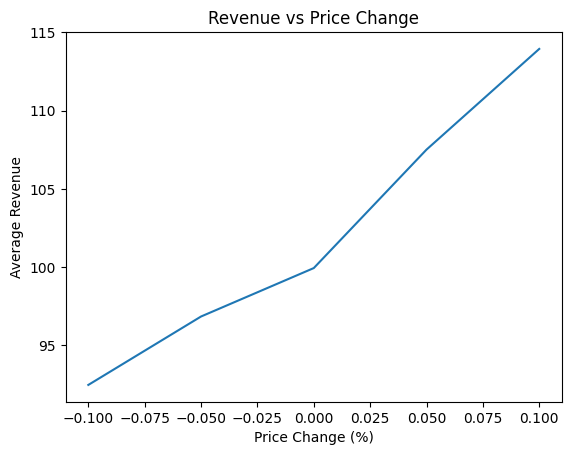

In [ ]:
import matplotlib.pyplot as plt

plt.figure()

plt.plot(
    sim_df['price_change_pct'],
    sim_df['avg_revenue']
)

plt.xlabel("Price Change (%)")
plt.ylabel("Average Revenue")
plt.title("Revenue vs Price Change")

plt.show()

In [ ]:
def simulate_price_change(model, df, features, sku, price_change_pct):

    sku_df = df[df['sku'] == sku].copy()

    sku_df['price_unit'] = sku_df['price_unit'] * (1 + price_change_pct)

    X_sim = sku_df[features]

    predicted_units = model.predict(X_sim)

    revenue = predicted_units * sku_df['price_unit']

    result = {
        "sku": sku,
        "price_change_pct": price_change_pct,
        "avg_units": predicted_units.mean(),
        "avg_revenue": revenue.mean()
    }

    return result

In [ ]:
scenarios = [-0.10, -0.05, 0, 0.05, 0.10]

results = []

In [ ]:
for pct in scenarios:

    res = simulate_price_change(
        demand_model,
        df,
        features,
        sku='JU-021',
        price_change_pct=pct
    )

    results.append(res)

In [ ]:
import pandas as pd

sim_df = pd.DataFrame(results)

print(sim_df)

      sku  price_change_pct  avg_units  avg_revenue
0  JU-021             -0.10  19.595226    92.479902
1  JU-021             -0.05  19.453827    96.849925
2  JU-021              0.00  19.101199    99.943395
3  JU-021              0.05  19.486420   107.509248
4  JU-021              0.10  19.678920   113.940737


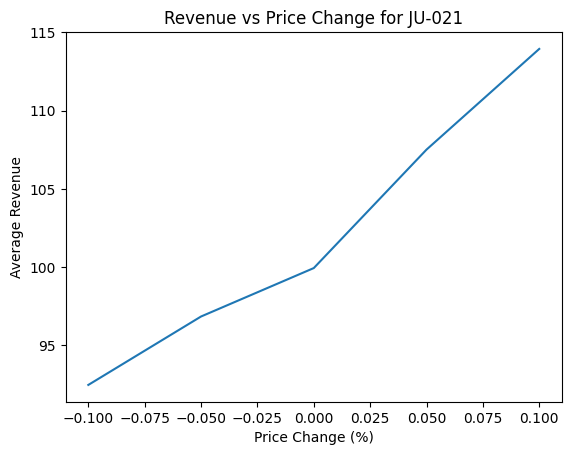

In [ ]:
import matplotlib.pyplot as plt

plt.figure()

plt.plot(
    sim_df['price_change_pct'],
    sim_df['avg_revenue']
)

plt.xlabel("Price Change (%)")
plt.ylabel("Average Revenue")
plt.title("Revenue vs Price Change for JU-021")

plt.show()

In [ ]:
def get_category_from_sku(sku):

    if sku.startswith("MI"):
        return "Milk"

    elif sku.startswith("JU"):
        return "Juice"

    elif sku.startswith("SN"):
        return "SnackBar"

    elif sku.startswith("RE"):
        return "ReadyMeal"

    elif sku.startswith("YO"):
        return "Yogurt"

    else:
        return "Unknown"


df['category'] = df['sku'].apply(get_category_from_sku)

In [ ]:
import matplotlib.pyplot as plt

def product_insights(product_name):

    print(f"\n📊 PRODUCT ANALYSIS FOR: {product_name}\n")

    product_df = df[df['category'] == product_name]

    summary = product_df.groupby('sku').agg({
        'price_unit': 'mean',
        'units_sold': 'mean'
    }).reset_index()

    print("📦 SKU Summary:")
    print(summary.head())



    trend_df = product_df.groupby('date')['units_sold'].sum()

    plt.figure()

    plt.plot(trend_df.index, trend_df.values)

    plt.xlabel("Date")
    plt.ylabel("Units Sold")
    plt.title(f"Demand Trend for {product_name}")

    plt.xticks(rotation=45)

    plt.show()



    sku_sample = product_df['sku'].iloc[0]

    scenarios = [-0.10, -0.05, 0, 0.05, 0.10]

    results = []

    for pct in scenarios:

        res = simulate_price_change(
            demand_model,
            df,
            features,
            sku_sample,
            pct
        )

        results.append(res)

    sim_df = pd.DataFrame(results)

    print("\n💰 Price Simulation:")
    print(sim_df)


    plt.figure()

    plt.plot(
        sim_df['price_change_pct'],
        sim_df['avg_revenue']
    )

    plt.xlabel("Price Change (%)")
    plt.ylabel("Revenue")

    plt.title(f"Revenue Optimization for {product_name}")

    plt.show()

    print("\n✅ Analysis Complete\n")


📊 PRODUCT ANALYSIS FOR: Milk

📦 SKU Summary:
      sku  price_unit  units_sold
0  MI-002    5.241931   19.152025
1  MI-006    5.252091   16.539280
2  MI-008    5.212837   19.137033
3  MI-011    5.223776   18.873799
4  MI-022    5.253678   16.809372


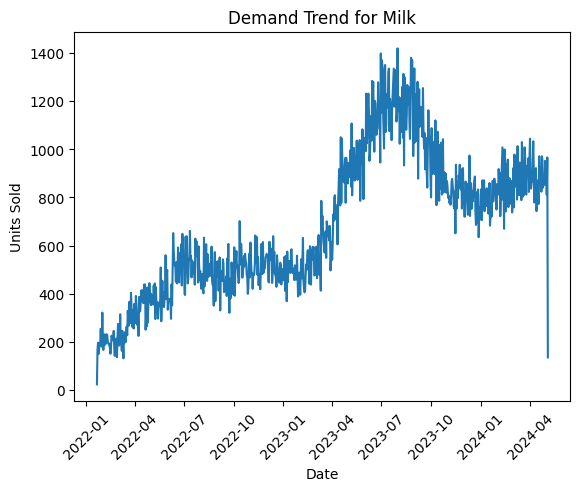


💰 Price Simulation:
      sku  price_change_pct  avg_units  avg_revenue
0  MI-006             -0.10  18.622620    87.766511
1  MI-006             -0.05  18.407385    91.574791
2  MI-006              0.00  17.900526    93.577747
3  MI-006              0.05  18.478762   101.923065
4  MI-006              0.10  18.713759   108.336893


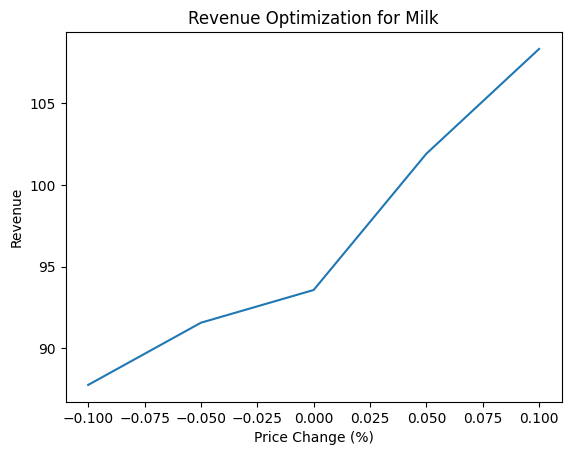


✅ Analysis Complete



In [ ]:
product_insights("Milk")


📊 PRODUCT ANALYSIS FOR: Juice

📦 SKU Summary:
      sku  price_unit  units_sold
0  JU-021    5.251364   18.228885


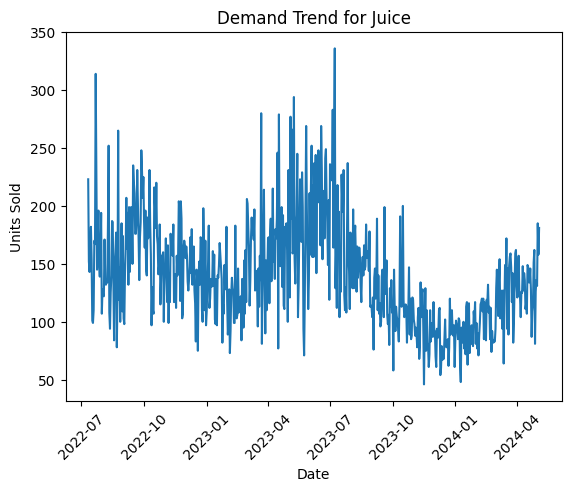


💰 Price Simulation:
      sku  price_change_pct  avg_units  avg_revenue
0  JU-021             -0.10  19.595226    92.479902
1  JU-021             -0.05  19.453827    96.849925
2  JU-021              0.00  19.101199    99.943395
3  JU-021              0.05  19.486420   107.509248
4  JU-021              0.10  19.678920   113.940737


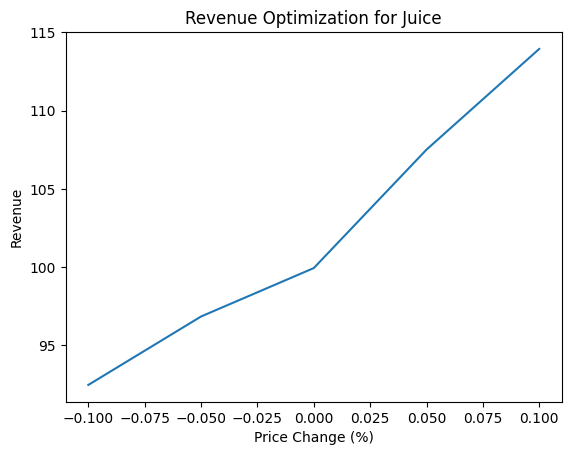


✅ Analysis Complete



In [ ]:
product_insights("Juice")


📊 PRODUCT ANALYSIS FOR: SnackBar

📦 SKU Summary:
      sku  price_unit  units_sold
0  SN-010    5.274930   20.513426
1  SN-013    5.239804   19.807776
2  SN-019    5.281925   20.924171
3  SN-027    5.242202   18.629138
4  SN-028    5.239254   21.467836


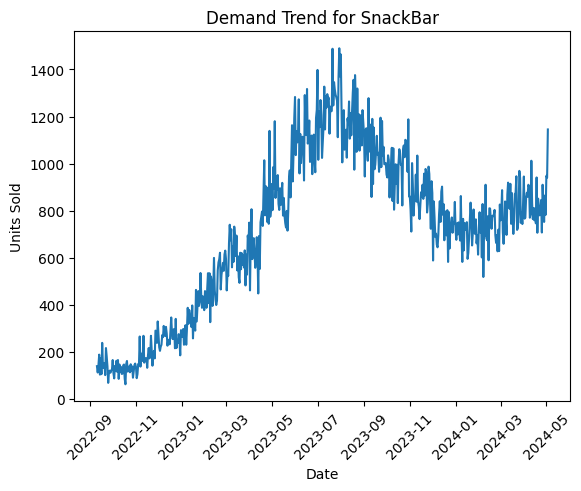


💰 Price Simulation:
      sku  price_change_pct  avg_units  avg_revenue
0  SN-027             -0.10  18.702278    88.265401
1  SN-027             -0.05  18.701461    93.211557
2  SN-027              0.00  18.700414    98.199466
3  SN-027              0.05  18.756958   103.621602
4  SN-027              0.10  18.802659   108.902968


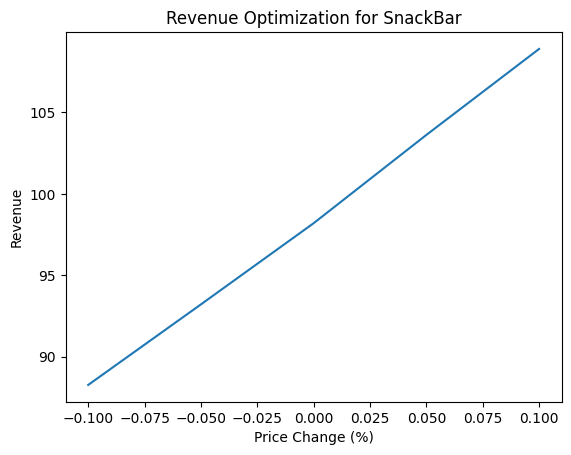


✅ Analysis Complete



In [ ]:
product_insights("SnackBar")

In [ ]:
cluster_labels = {
    0: "Stable Demand",
    1: "Low Volume Premium",
    2: "High Promotion Sensitive",
    3: "Declining Demand"
}

In [ ]:
def elasticity_label(value):

    if value < -1:
        return "Highly Elastic"

    elif -1 <= value < -0.1:
        return "Moderately Elastic"

    elif -0.1 <= value <= 0.1:
        return "Inelastic"

    else:
        return "Positive/Unusual"

In [ ]:
def generate_recommendation(cluster, elasticity, promo_effect):

    recommendation = []

    if cluster == 0:
        recommendation.append(
            "Maintain stable pricing and inventory."
        )

    elif cluster == 1:
        recommendation.append(
            "Use premium pricing strategy."
        )

    elif cluster == 2:
        recommendation.append(
            "Use promotions aggressively."
        )

    elif cluster == 3:
        recommendation.append(
            "Consider discounting or repositioning."
        )

    if elasticity < -0.5:
        recommendation.append(
            "Avoid price increases — demand sensitive."
        )

    elif -0.1 <= elasticity <= 0.1:
        recommendation.append(
            "Safe to increase price slightly."
        )

    if promo_effect > 0.6:
        recommendation.append(
            "Promotions significantly boost demand."
        )

    return recommendation

In [ ]:
def product_recommendation(product_name):

    print(f"\n📊 BUSINESS RECOMMENDATION FOR: {product_name}\n")

    product_df = df[df['category'] == product_name]


    if product_df.empty:
        print(f"No data found for product category: {product_name}.")
        return

    top_sku = get_top_sku(product_df)


    if top_sku not in sku_metrics_df['sku'].values:
        print(f"Top SKU ({top_sku}) not found in sku_metrics_df. Attempting to find an alternative SKU for {product_name}.")
        found_sku_in_metrics = False
        for sku_candidate in product_df['sku'].unique():
            if sku_candidate in sku_metrics_df['sku'].values:
                top_sku = sku_candidate
                found_sku_in_metrics = True
                print(f"Using alternative SKU: {top_sku} for recommendation.")
                break
        if not found_sku_in_metrics:
            print(f"No suitable SKU found in sku_metrics_df for {product_name}. Cannot provide recommendation.")
            return

    sku_sample = top_sku
    sku_data = sku_metrics_df[
        sku_metrics_df['sku'] == sku_sample
    ].iloc[0]

    cluster_data = sku_metrics_df[
        sku_metrics_df['sku'] == sku_sample
    ].iloc[0]

    elasticity = sku_data['elasticity']
    promo_effect = sku_data['promo_effect']
    cluster = cluster_data['cluster']

    cluster_name = cluster_labels[cluster]

    elasticity_type = elasticity_label(elasticity)

    recommendations = generate_recommendation(
        cluster,
        elasticity,
        promo_effect
    )

    print(f"📦 SKU: {sku_sample}")
    print(f"📊 Cluster Type: {cluster_name}")
    print(f"📉 Elasticity: {elasticity_type}")
    print(f"📢 Promotion Impact: {promo_effect:.2f}")

    print("\n💡 RECOMMENDATIONS:")

    for rec in recommendations:
        print(f"• {rec}")

    print("\n✅ Recommendation Complete\n")

In [ ]:
product_recommendation("Milk")


📊 BUSINESS RECOMMENDATION FOR: Milk

Top SKU: MI-026
📦 SKU: MI-026
📊 Cluster Type: High Promotion Sensitive
📉 Elasticity: Inelastic
📢 Promotion Impact: 0.68

💡 RECOMMENDATIONS:
• Use promotions aggressively.
• Safe to increase price slightly.
• Promotions significantly boost demand.

✅ Recommendation Complete



In [ ]:
product_recommendation("Juice")


📊 BUSINESS RECOMMENDATION FOR: Juice

Top SKU: JU-021
📦 SKU: JU-021
📊 Cluster Type: Stable Demand
📉 Elasticity: Inelastic
📢 Promotion Impact: 0.66

💡 RECOMMENDATIONS:
• Maintain stable pricing and inventory.
• Safe to increase price slightly.
• Promotions significantly boost demand.

✅ Recommendation Complete



In [ ]:
product_recommendation("SnackBar")


📊 BUSINESS RECOMMENDATION FOR: SnackBar

Top SKU: SN-027
📦 SKU: SN-027
📊 Cluster Type: Low Volume Premium
📉 Elasticity: Inelastic
📢 Promotion Impact: 0.66

💡 RECOMMENDATIONS:
• Use premium pricing strategy.
• Safe to increase price slightly.
• Promotions significantly boost demand.

✅ Recommendation Complete



In [ ]:
final_summary = sku_metrics_df.copy()

final_summary['cluster_type'] = final_summary['cluster'].map(
    cluster_labels
)

final_summary['elasticity_type'] = final_summary[
    'elasticity'
].apply(elasticity_label)

print(final_summary.head())

      sku  elasticity  promo_effect     trend  avg_price  avg_units  cluster  \
0  MI-006   -0.013196      0.648319 -0.000062   5.251204  16.533302        0   
1  MI-026   -0.003440      0.676979 -0.000007   5.216655  18.610439        2   
2  MI-023    0.022283      0.682790 -0.000015   5.195243  18.452132        1   
3  JU-021   -0.016650      0.660089 -0.000099   5.251364  18.228885        0   
4  SN-027    0.009242      0.655594 -0.000105   5.242202  18.629138        1   

               cluster_type elasticity_type  
0             Stable Demand       Inelastic  
1  High Promotion Sensitive       Inelastic  
2        Low Volume Premium       Inelastic  
3             Stable Demand       Inelastic  
4        Low Volume Premium       Inelastic  
